In [1]:
#autoreload:
%load_ext autoreload
%autoreload 2
import anndata as ad
%matplotlib inline
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

import copy


from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from skmisc.loess import loess


from pathlib import Path
import sys, os
sys.path.append(os.path.abspath("/code"))  

#from bg_spatial_plots.normalization import section_block_normalization

from bg_spatial_plots.figure_utils import add_scalebar
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from bg_spatial_plots.figure_utils import plot_spatial_subset, plot_spatial_gene_expression
from bg_spatial_plots.gradient_utils import (run_pca_on_spatial_cells, estimate_global_gradient,
                                             add_pcs_to_obs, project_2d_points_to_line, add_pc_gradient_arrow_to_section, 
                                             add_pc_local_gradient_arrows_to_section, plot_gene_depth_heatmap,
                                              find_best_gradient_pc, plot_cells_and_line, get_top_pc_genes, 
                                             plot_pc_on_single_plane,
                                              get_pc_spatial_spread, run_gradient_analysis)

from bg_spatial_plots.constants_color_palettes import CURRENT_COLOR_DICT_OF_DICTS



In [2]:

all_SPNs = ['STRd D2 Matrix SPN',
 'STRd D1 Striosome SPN',
 'STRd D2 Striosome SPN',
 'STRd D1 Matrix SPN',  
  'STRv D2 SPN',
 'STRv D1 SPN']
matrix_groups =[ 'STRd D1 Matrix SPN','STRd D2 Matrix SPN']
dorsal_SPN_groups =  [ 'STRd D1 Matrix SPN','STRd D2 Matrix SPN', 'STRd D1 Striosome SPN','STRd D2 Striosome SPN']
striosome_groups  =  [ 'STRd D1 Striosome SPN','STRd D2 Striosome SPN']
non_strio_groups = [g for g in all_SPNs if g not in striosome_groups]




- subset to Groups and sections of interest
- use a manually-defined line as a seed for subsequent analysis
- the strength and consistency of this gradient across sections and species suggests that an automatic selection could be feasible (discussed more below)

In [3]:

# z planes chosen for gradient analysis and figures
# marmoset
cj_z_choice = 12
cj_z_choices = [10,11,12,13,14,15,16,17,18]

# human :
hs_z_choice = 6
hs_z_choices  = [5,6,7,8]

# macaque :

mm_z_choice = 8
mm_z_choices = [6,7,8,9]


## PCA calculation

cell below runs PCA on all SPNs, results in AnnData objects saved in `SPNs_with_PCA_batch_log1p`

In [4]:

N_PCs_TO_KEEP = 10
LAYER_TO_USE_FOR_GENE_FILTERING = "batch_normalized"
LAYER_TO_USE = "batch_normalized_log1p"
MIN_MEAN_EXPRESSION = 0.25

# first remove genes with mean counts in SPNs < MIN_MEAN_EXPRESSION :


# gene_count_means = np.mean(cj_SPN_ad.layers[LAYER_TO_USE_FOR_GENE_FILTERING], axis=0)
# genes_to_keep = gene_count_means >MIN_MEAN_EXPRESSION
# cj_SPN_ad = cj_SPN_ad[:,cj_SPN_ad.var_names[genes_to_keep.flat].tolist()].copy()
# print("kept "+str(np.sum(genes_to_keep))+" genes")


# gene_count_means = np.mean(mm_SPN_ad.layers[LAYER_TO_USE_FOR_GENE_FILTERING], axis=0)
# genes_to_keep = gene_count_means >MIN_MEAN_EXPRESSION
# mm_SPN_ad = mm_SPN_ad[:,mm_SPN_ad.var_names[genes_to_keep.flat].tolist()].copy()
# print("kept "+str(np.sum(genes_to_keep))+" genes")


# gene_count_means = np.mean(hs_SPN_ad.layers[LAYER_TO_USE_FOR_GENE_FILTERING], axis=0)
# genes_to_keep = gene_count_means >MIN_MEAN_EXPRESSION
# hs_SPN_ad = hs_SPN_ad[:,hs_SPN_ad.var_names[genes_to_keep.flat].tolist()].copy()
# print("kept "+str(np.sum(genes_to_keep))+" genes")


# # run on all SPNs
# run_pca_on_spatial_cells(cj_SPN_ad, pca_n_comps=N_PCs_TO_KEEP, layer=LAYER_TO_USE, normalize=False, scale=True)
# add_pcs_to_obs(cj_SPN_ad, list(range(N_PCs_TO_KEEP)))

# run_pca_on_spatial_cells(mm_SPN_ad, pca_n_comps=N_PCs_TO_KEEP, layer=LAYER_TO_USE, normalize=False, scale=True)
# add_pcs_to_obs(mm_SPN_ad, list(range(N_PCs_TO_KEEP)))



# run_pca_on_spatial_cells(hs_SPN_ad, pca_n_comps=N_PCs_TO_KEEP, layer=LAYER_TO_USE, normalize=False, scale=True)
# add_pcs_to_obs(hs_SPN_ad, list(range(N_PCs_TO_KEEP)))





In [5]:
# load in  PCA results:

mm_SPN_ad = ad.read_h5ad("/root/capsule/data/SPNs_with_PCA_batch_log1p/Macaque_SPNs_with_PCA_batch_log.h5ad")
cj_SPN_ad = ad.read_h5ad("/root/capsule/data/SPNs_with_PCA_batch_log1p/Marmoset_SPNs_with_PCA_batch_log.h5ad")
hs_SPN_ad = ad.read_h5ad("/root/capsule/data/SPNs_with_PCA_batch_log1p/Human_SPNs_with_PCA_batch_log.h5ad")




In [6]:
# annotation changes move one human cluster from matrix to striosome (see Methods)
cluster_mask = (hs_SPN_ad.obs['Cluster'] == 'Human-23')
hs_SPN_ad.obs.loc[cluster_mask, 'Group'] = 'STRd D1 Matrix SPN'

In [7]:
# # flip sign on all PCs for macaque and human 
pc_cols = [c for c in mm_SPN_ad.obs.columns if "PC" in c]
mm_SPN_ad.obs.loc[:,pc_cols] = -mm_SPN_ad.obs.loc[:,pc_cols].values.copy()
hs_SPN_ad.obs.loc[:,pc_cols] = -hs_SPN_ad.obs.loc[:,pc_cols].values.copy()


In [8]:
LIST_TO_RUN = [
    {
        'species': "Marmoset",
        'species_ad': cj_SPN_ad,
        'z_choices': cj_z_choices,
        'z_choice': cj_z_choice,
        'line': [[2000, 10000], [5000, 7000]],
        'coord_cols': ["x_slab_um", "y_slab_um"],
        'grid_spacing': 500,
        'arrow_size': 4000,
        'cell_marker_size': 1.5,
    },
    {
        'species': "Macaque",
        'species_ad': mm_SPN_ad,
        'z_choices': mm_z_choices,
        'z_choice': mm_z_choice,
        'line': [[42000, 32000], [48000, 26000]],
        'coord_cols': ["x_slab_um", "y_slab_um"],
        'grid_spacing': 1000,
        'arrow_size': 10000,
        'cell_marker_size': .5,
    },
    {
        'species': "Human",
        'species_ad': hs_SPN_ad,
        'z_choices': hs_z_choices,
        'z_choice': hs_z_choice,
        'line': [[20000, 80000], [30000, 60000]],
        'coord_cols': ["x_slab_um", "y_slab_um"],
        'grid_spacing': 1200,
        'arrow_size': 20000,
        'cell_marker_size': .5,
    },
]


Marmoset
PC2 (index: 1) has the highest correlation to projected depth: 0.738
1 1 True
[ 2445.52671863 -3165.3434361 ]
[array([21271.64875006, 14954.18441336]), array([23717.17546869, 11788.84097726])]


/code/bg_spatial_plots/gradient_utils.py:1191: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


SPOCK1 5.7713866
SCN4B 22.34091
PLCXD3 1.2701632
ST6GALNAC5 3.37803
TESPA1 2.9249415
JCAD 6.0829835
GPRIN3 3.3250582
CSGALNACT1 0.44632867
LOC100385731 1.975641
GLRA3 0.4292541
CCDC85A 0.41048953
CNR1 1.8770978
GULP1 1.5814103
FAM135B 2.873135
SYT10 1.2086246
ABLIM1 0.52039635
GDA 8.068415
MPPED1 0.8335664
SPON1 1.8412005
LHFPL6 0.5527972
PPP1R1B 47.51387
CRYM 18.737938
L3MBTL4 0.8821096
LMO1 0.28566435
Macaque
PC2 (index: 1) has the highest correlation to projected depth: -0.733
1 1 True
[ 6121.69484751 -7907.26578496]
[array([41862.29411856, 31181.04597307]), array([47983.98896607, 23273.78018811])]


/code/bg_spatial_plots/gradient_utils.py:1191: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


GDA 3.1831861215422856
COL25A1 6.728063680118474
PMFBP1 2.3678267308404295
HPCA 37.414555455651346
TESPA1 2.248452953932406
CNR1 18.359126249537205
SNTG2 1.8897498281059926
NELL1 3.1419315597397786
MME 10.09879938647062
CSGALNACT1 0.7803987940974242
KCTD17 23.54416353731422
BRINP3 1.2925107103189295
PRKG1 0.8871581953773733
CHRM3 2.3744115935896755
DPP10 2.004389908499497
SYT2 12.189691648595758
COL5A2 15.05267890199397
HTR2C 2.1194531126037974
GULP1 2.380970011106997
PPP1R1B 108.15155762416036
SLC24A2 34.94904003808114
MOXD1 0.5664833130586555
SEMA3E 2.4816998995081185
ALCAM 6.6008885597926685
Human
PC2 (index: 1) has the highest correlation to projected depth: -0.384
1 1 True


/code/bg_spatial_plots/gradient_utils.py:1080: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=[10, 5])


[ 13064.37728514 -15143.38291636]
[array([16898.89025357, 78802.62978706]), array([29963.26753871, 63659.2468707 ])]


/code/bg_spatial_plots/gradient_utils.py:1191: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


ARHGAP6 0.48748630050845315
GDA 0.32215814154045164
TESPA1 1.1013133545338578
PDE10A 23.250705186941914
CHRM3 0.6912269354461991
SLC35F1 0.616018972672883
LOXHD1 1.6376866274995956
NEFM 9.97664348982195
MEIS3 0.22891176629116577
LINGO2 0.34138234607161455
CNR1 5.662947591584469
PDE1C 0.31322876803392075
ADORA2A 15.796115632691928
LPL 5.519592518730124
TUNAR 3.962342118974469
COL5A3 0.4375572683663019
RGS6 0.8132557178533569
KCTD12 2.8642268096803747
RGS4 2.0150020661528236
CA12 3.7209256364649024
HS3ST4 1.4293106236188216
LYPD1 0.34488582259832185
KCNIP1 0.43649724213514424
GRIK3 0.9909448606694333


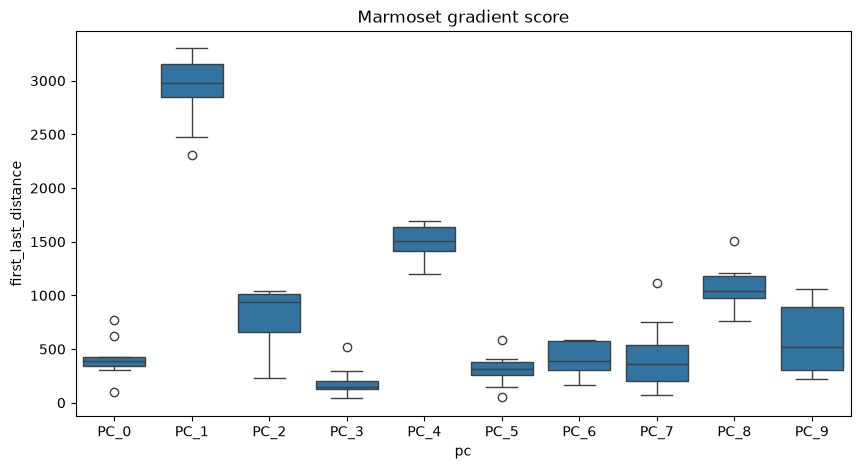

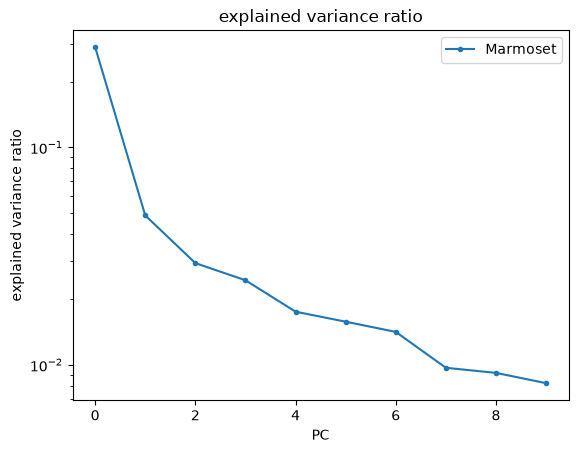

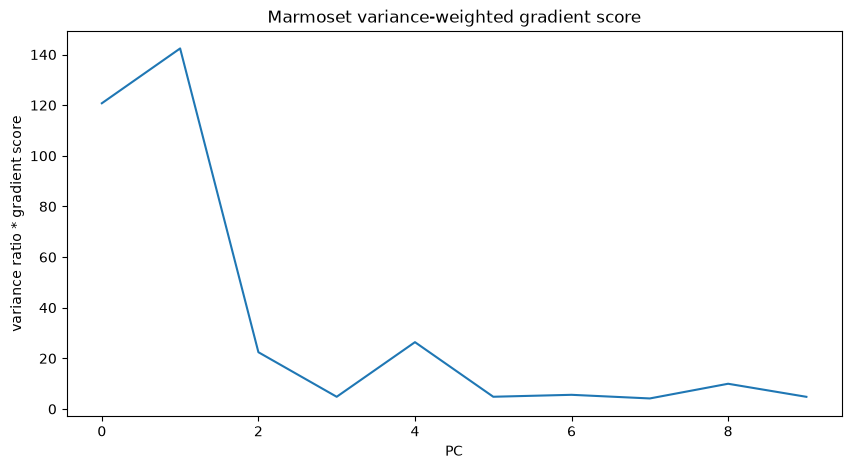

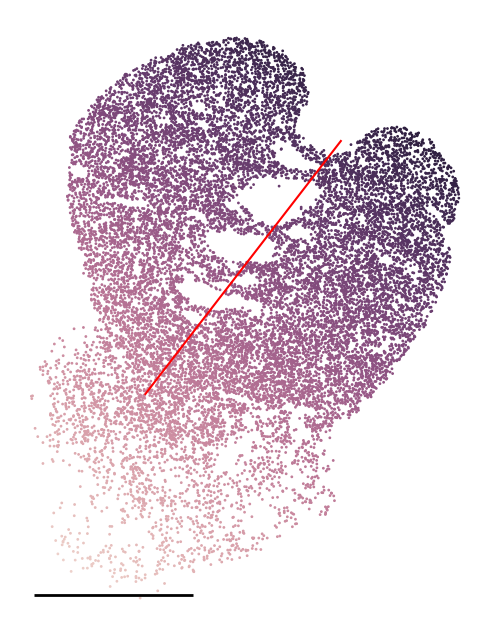

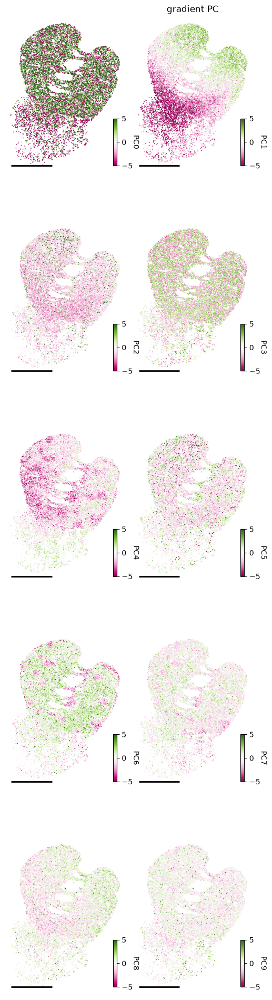

...

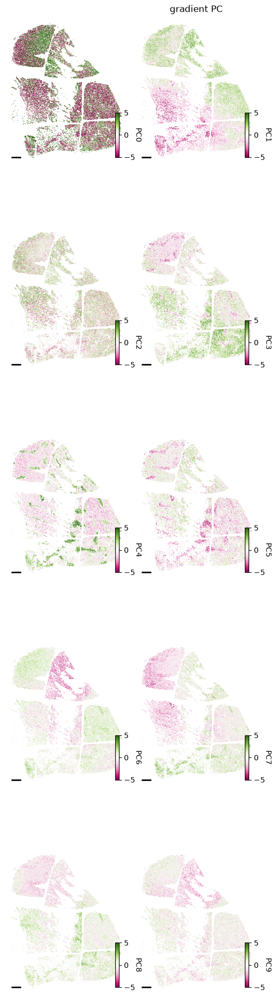

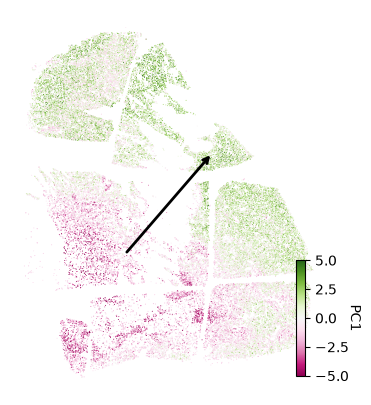

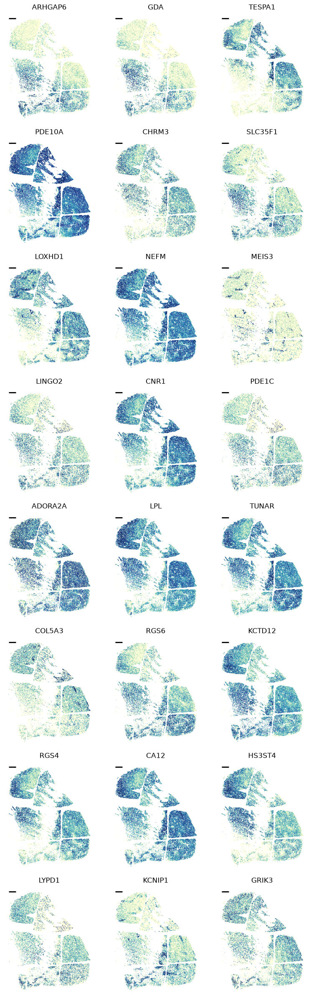

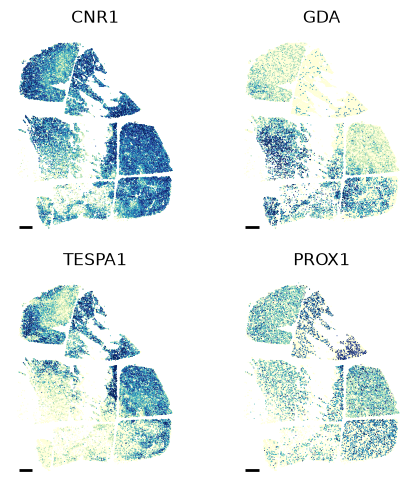

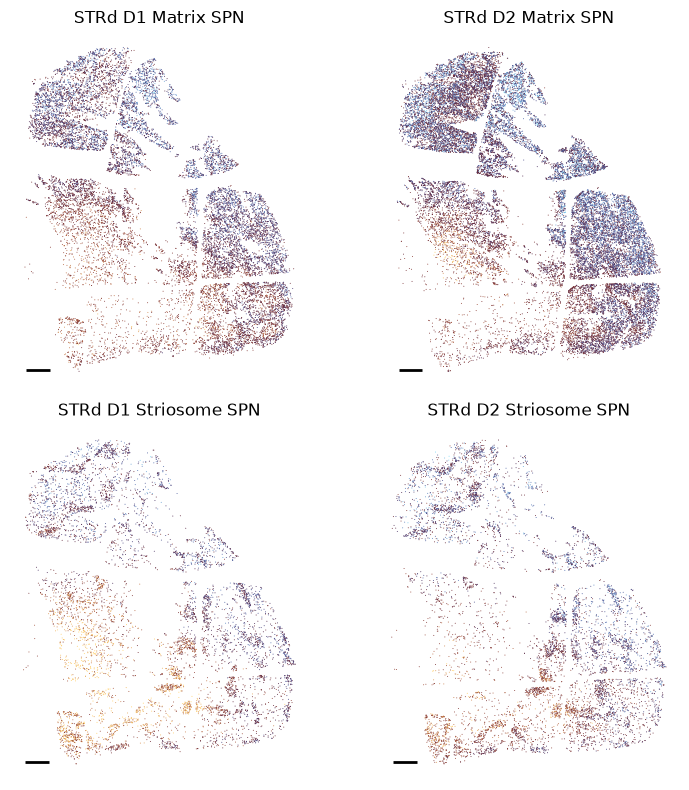

In [9]:

FIGURE_4_PANEL_NAMES = ["batch_normalized_log1p_dorsal_SPNs_Human_PC_in_SPN_groups",
"batch_normalized_log1p_dorsal_SPNs_Macaque_PC_in_SPN_groups",
"batch_normalized_log1p_dorsal_SPNs_Marmoset_PC_in_SPN_groups",
"batch_normalized_log1p_Human_gradient_direction",
"batch_normalized_log1p_Macaque_gradient_direction",
"batch_normalized_log1p_Marmoset_gradient_direction",
"batch_normalized_log1p_dorsal_SPNs_Marmoset_4_geneplot",
"batch_normalized_log1p_dorsal_SPNs_Macaque_4_geneplot",
"batch_normalized_log1p_dorsal_SPNs_Human_4_geneplot",
"brl_batch_normalized_log1p_dorsal SPNs_Human_depth_heatmap",
"brl_batch_normalized_log1p_dorsal SPNs_Macaque_depth_heatmap",
"brl_batch_normalized_log1p_dorsal SPNs_Marmoset_depth_heatmap"]





SUPPLEMENTAL_PANEL_NAMES = ["batch_normalized_log1p_dorsal_SPNs_Macaque_24_geneplot",
"batch_normalized_log1p_dorsal_SPNs_Marmoset_24_geneplot",
"batch_normalized_log1p_dorsal_SPNs_Human_24_geneplot",
"batch_normalized_log1p_dorsal_SPNs_Human_PCs_plot",
"batch_normalized_log1p_dorsal_SPNs_Macaque_PCs_plot",
"batch_normalized_log1p_dorsal_SPNs_Marmoset_PCs_plot",
"Human_gradient_scores",
"Macaque_gradient_scores",
"Marmoset_gradient_scores",
"angle_distribution"]



JUST_DO_ONE = False
CLOSE_FIGS = False


# all_spn_results = run_gradient_analysis(list_to_run = LIST_TO_RUN, layer_to_use=LAYER_TO_USE,
#                                      selected_group_name="all_SPNs", selected_groups=all_SPNs,
#                                      just_do_one=JUST_DO_ONE, close_figs=CLOSE_FIGS, n_pcs_to_keep = N_PCs_TO_KEEP)


dorsal_spn_results = run_gradient_analysis(list_to_run = LIST_TO_RUN, layer_to_use=LAYER_TO_USE,
                                     selected_group_name="dorsal_SPNs", selected_groups=dorsal_SPN_groups,
                                     just_do_one=JUST_DO_ONE, close_figs=CLOSE_FIGS, n_gene_plot_rows=8,  
                                     n_pcs_to_keep = N_PCs_TO_KEEP, main_figure_panels=FIGURE_4_PANEL_NAMES,
                                     supp_figure_panels=SUPPLEMENTAL_PANEL_NAMES)


In [10]:
# pc_spread_info.groupby("pc").first_last_distance.mean()

# pc_means = pc_spread_info.groupby("pc").first_last_distance.mean()
# max_pc_index = pc_means.argmax()
# best_pc = int(pc_means.index[max_pc_index].strip("PC_"))

In [11]:
# pull top 10 genes in each direction from each species:
for data_index in range(3):
    species = LIST_TO_RUN[data_index]["species"]
    if data_index==0:
        list_of_gene_records=[]
    if species=="Marmoset":
        pos = get_top_pc_genes(LIST_TO_RUN[data_index]["species_ad"], 1, top_n=20, kind='positive')
        neg = get_top_pc_genes(LIST_TO_RUN[data_index]["species_ad"], 1, top_n=20, kind='negative')
    else:
        # these PC signs are switched...
        neg = get_top_pc_genes(LIST_TO_RUN[data_index]["species_ad"], 1, top_n=20, kind='positive')
        pos = get_top_pc_genes(LIST_TO_RUN[data_index]["species_ad"], 1, top_n=20, kind='negative')        
    list_of_gene_records.extend([{"gene":g,"sign":"positive","species":species} for g in pos])
    list_of_gene_records.extend([{"gene":g,"sign":"negative","species":species} for g in neg])
list_df = pd.DataFrame.from_records(list_of_gene_records)

list_df.to_csv("/scratch/PCg_supplemental/gene_list.csv")
print(list_df)

        gene      sign   species
0     SPOCK1  positive  Marmoset
1      SCN4B  positive  Marmoset
2     TESPA1  positive  Marmoset
3       JCAD  positive  Marmoset
4     GPRIN3  positive  Marmoset
..       ...       ...       ...
115     FAT1  negative     Human
116     MPDZ  negative     Human
117     ETV1  negative     Human
118  SPATS2L  negative     Human
119    PTPRQ  negative     Human

[120 rows x 3 columns]


1
1
1


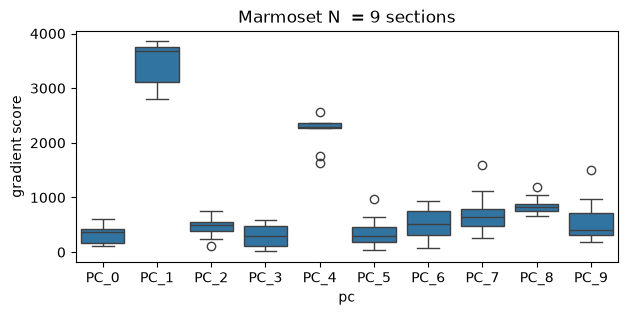

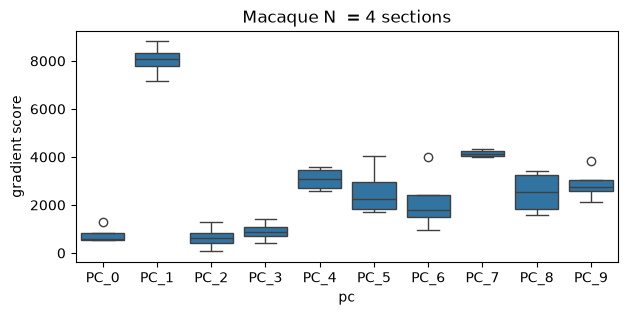

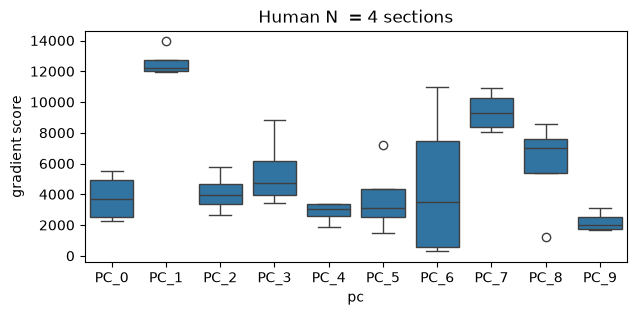

In [12]:
# revisit the plotting of the gradient distance:

# now find the best PC computationally:
PERCENTILE_BINS = 5
for ii in range(3):
    species_string = LIST_TO_RUN[ii]["species"]

    adobj = LIST_TO_RUN[ii]["species_ad"]
    pc_spread_info = get_pc_spatial_spread(
        adobj.obs.copy(),
        multi_section_column="z_order",
        multi_section_values=LIST_TO_RUN[ii]["z_choices"],
        spatial_obs_columns=LIST_TO_RUN[ii]["coord_cols"],
        percentile_bins=PERCENTILE_BINS,
        plot_stuff=False,savefig_path=Path("/root/capsule/scratch/PCg_supplemental/gradient_overview_"+species_string+".png"),
         slices_to_save = [LIST_TO_RUN[ii]["z_choice"]],
    )

    max_pc_index = pc_spread_info.groupby("pc").first_last_distance.mean().argmax()
    best_pc = int(pc_spread_info.groupby("pc").mean().iloc[max_pc_index].name.strip("PC_"))
    # store for later use...

    print(best_pc)
    adobj.uns["best_pc"] = best_pc
    # this matches the best gradient PC (chosen by alignment to the manual line)

    plt.figure(figsize=[7, 3])
    sns.boxplot(pc_spread_info, x="pc", y="first_last_distance")
    plt.title(species_string+" N  = "+str(len(LIST_TO_RUN[ii]["z_choices"]))+ " sections")
    plt.ylabel("gradient score")
    plt.savefig("/scratch/figure_4_panels/SUPP_"+species_string+"_gradient_scores.svg")



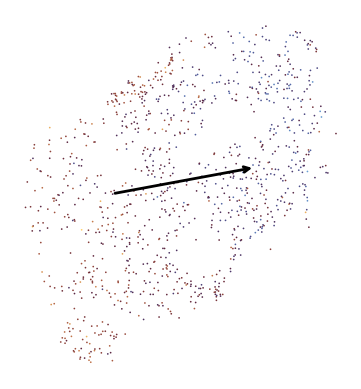

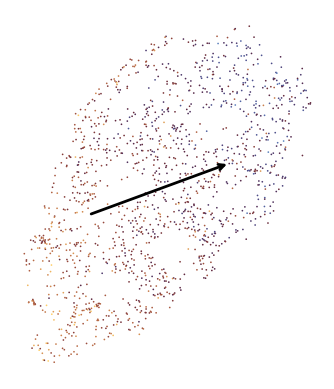

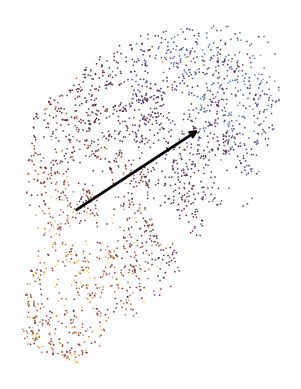

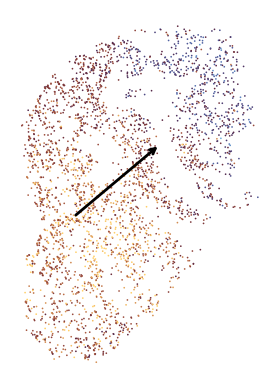

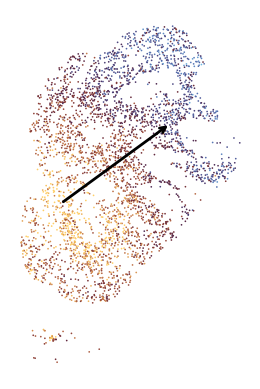

...

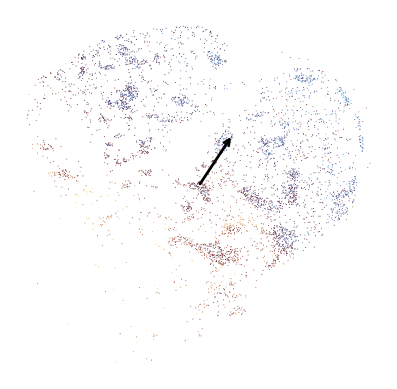

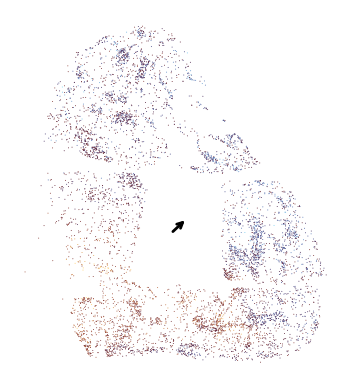

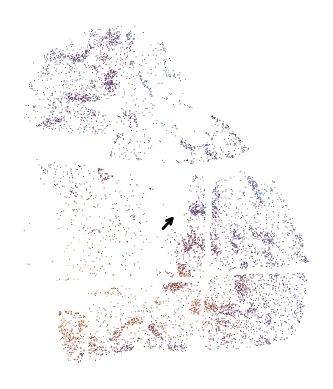

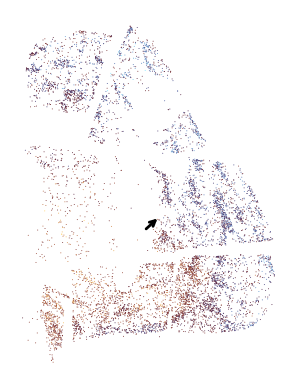

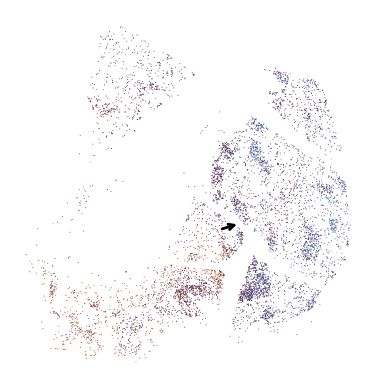

In [13]:
# # TODO:

def angle(v0, v1):
    v0 = np.asarray(v0, dtype=float).reshape(-1)
    v1 = np.asarray(v1, dtype=float).reshape(-1)
    dot_mag = np.dot(v0, v1) / (np.linalg.norm(v0) * np.linalg.norm(v1))
    dot_mag = np.clip(dot_mag, -1.0, 1.0)
    return float(np.arccos(dot_mag))


X_AXIS_VECTOR = [1,0]

gradient_vector_records = []
for SPN_Group in dorsal_SPN_groups:
    for species_index in range(3):
        # 1. extract gradient line from each section based on chosen PC
        if species_index == 0:
            z_to_plot = list(range(3, 26))
        elif species_index == 1:
            z_to_plot = list(range(4, 10))
        else:
            z_to_plot = LIST_TO_RUN[species_index]["z_choices"]

        for z in z_to_plot:
            species_ad = LIST_TO_RUN[species_index]["species_ad"]
            gs = species_ad[np.logical_and(species_ad.obs.Group.isin([SPN_Group]), species_ad.obs.z_order == z), :]
            # update to ensure correct PC:
            best_pc = 1
            # plot a section and gradient line
            fig, ax = plt.subplots()
            g = plot_pc_on_single_plane(
                gs,
                spatial_keys=LIST_TO_RUN[species_index]["coord_cols"],
                pc_index=best_pc,
                vlim_abs=5,
                marker_size=LIST_TO_RUN[species_index]["cell_marker_size"],
                cmap=sns.color_palette("managua", as_cmap=True),
                ax=ax,
            )

            add_pc_gradient_arrow_to_section(
                ax,
                gs.obs.loc[:, LIST_TO_RUN[species_index]["coord_cols"]].values,
                gs.obs.loc[:, "PC_" + str(best_pc)].values.ravel(),
                arrow_scale=300,
                arrow_color="black",
                arrow_linewidth=2,
                arrow_alpha=1,
            )

            plt.show()

            # calculate angle to the X axis
            sign_switch = 1

            gradient_vector = (
                sign_switch
                * estimate_global_gradient(
                    gs.obs.loc[:, LIST_TO_RUN[species_index]["coord_cols"]].values,
                    gs.obs.loc[:, ["PC_" + str(best_pc)]].values,
                )
            ).flatten().astype(float)

            # repeat angle calculation to the manual vector:

            manual_vector = np.diff(np.array(LIST_TO_RUN[species_index]["line"]), axis=0).flatten().astype(float)

            gradient_vector_record = dict(
                species=LIST_TO_RUN[species_index]["species"],
                z=z,
                gradient_vector=gradient_vector,
                manual_vector=manual_vector,
                angle=angle(gradient_vector, X_AXIS_VECTOR),
                mean_gradient_pc=float(gs.obs["PC_" + str(1)].mean()),
                Group=SPN_Group,
                angle_to_manual = angle(gradient_vector, manual_vector),
                angle_of_manual = angle(manual_vector, X_AXIS_VECTOR)
            )

            gradient_vector_records.append(gradient_vector_record)

gradient_results = pd.DataFrame.from_records(gradient_vector_records)

In [14]:
gradient_results

,species,z,gradient_vector,manual_vector,angle,mean_gradient_pc,Group,angle_to_manual,angle_of_manual
0,Marmoset,3,"[0.0014147428143308444, -0.0002618461634479367]","[3000.0, -3000.0]",0.183013,-0.249322,STRd D1 Matrix SPN,0.602385,0.785398
1,Marmoset,4,"[0.0014555742527389785, -0.0005344855689973896]","[3000.0, -3000.0]",0.351914,-0.910474,STRd D1 Matrix SPN,0.433484,0.785398
2,Marmoset,5,"[0.0013719731044876276, -0.0008980733229344437]","[3000.0, -3000.0]",0.579592,-0.568228,STRd D1 Matrix SPN,0.205806,0.785398
3,Marmoset,6,"[0.0009548659580628075, -0.0008008944339454525]","[3000.0, -3000.0]",0.697927,-1.800446,STRd D1 Matrix SPN,0.087471,0.785398
4,Marmoset,7,"[0.0012586000222588928, -0.0009195234114669993]","[3000.0, -3000.0]",0.630964,-1.308640,STRd D1 Matrix SPN,0.154434,0.785398
...,...,...,...,...,...,...,...,...,...
127,Macaque,9,"[0.00030506992701772467, -0.0004611674884021571]","[6000.0, -6000.0]",0.986368,0.060734,STRd D2 Striosome SPN,0.200970,0.785398
128,Human,5,"[0.00012594734784785927, -0.00011803954072761034]","[10000.0, -20000.0]",0.752999,-0.164488,STRd D2 Striosome SPN,0.354150,1.107149
129,Human,6,"[0.00012204808199046378, -0.0001370573151502833]","[10000.0, -20000.0]",0.843261,-0.235347,STRd D2 Striosome SPN,0.263888,1.107149
130,Human,7,"[0.00012932369388657313, -0.00011840509778525594]","[10000.0, -20000.0]",0.741352,-0.254598,STRd D2 Striosome SPN,0.365797,1.107149


In [15]:
gradient_results.loc[gradient_results.species==LIST_TO_RUN[ii]["species"],:]

,species,z,gradient_vector,manual_vector,angle,mean_gradient_pc,Group,angle_to_manual,angle_of_manual
29,Human,5,"[8.862827732226208e-05, -0.0001409747382564025]","[10000.0, -20000.0]",1.009554,0.071344,STRd D1 Matrix SPN,0.097595,1.107149
30,Human,6,"[9.844184129142613e-05, -0.00014546750775422035]","[10000.0, -20000.0]",0.975861,-0.034725,STRd D1 Matrix SPN,0.131288,1.107149
31,Human,7,"[0.00012700940506639737, -0.00014552191626321395]","[10000.0, -20000.0]",0.853222,-0.053958,STRd D1 Matrix SPN,0.253927,1.107149
32,Human,8,"[0.00012182845339262761, -9.476070243487822e-05]","[10000.0, -20000.0]",0.661070,0.121157,STRd D1 Matrix SPN,0.446079,1.107149
62,Human,5,"[9.354018365902023e-05, -0.00010578338530595236]","[10000.0, -20000.0]",0.846745,0.636260,STRd D2 Matrix SPN,0.260404,1.107149
63,Human,6,"[0.0001139878576320341, -0.00011934371161024406]","[10000.0, -20000.0]",0.808348,0.529734,STRd D2 Matrix SPN,0.298801,1.107149
64,Human,7,"[0.0001313276612561124, -0.00012134044575379226]","[10000.0, -20000.0]",0.745892,0.548269,STRd D2 Matrix SPN,0.361257,1.107149
65,Human,8,"[0.0001182717308622384, -6.12699389860758e-05]","[10000.0, -20000.0]",0.477978,0.693650,STRd D2 Matrix SPN,0.629170,1.107149
95,Human,5,"[0.00017222876163485565, -0.000172649690200915]","[10000.0, -20000.0]",0.786619,-0.934077,STRd D1 Striosome SPN,0.320530,1.107149
96,Human,6,"[0.0001737940172791778, -0.00019842855794756305]","[10000.0, -20000.0]",0.851484,-0.981303,STRd D1 Striosome SPN,0.255665,1.107149


<Figure size 640x480 with 0 Axes>

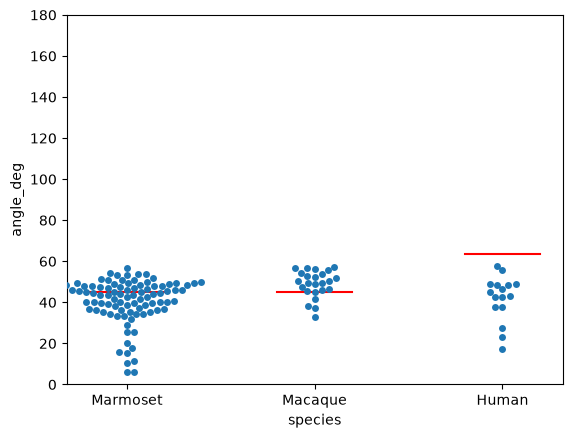

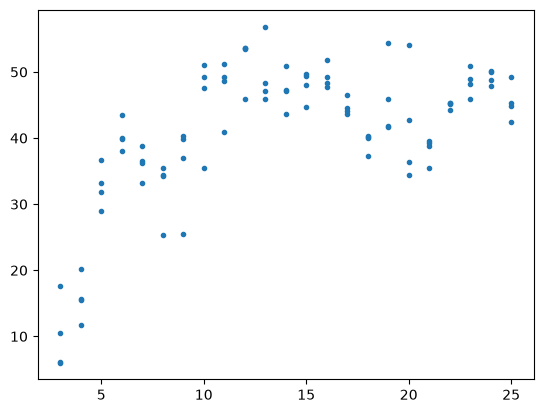

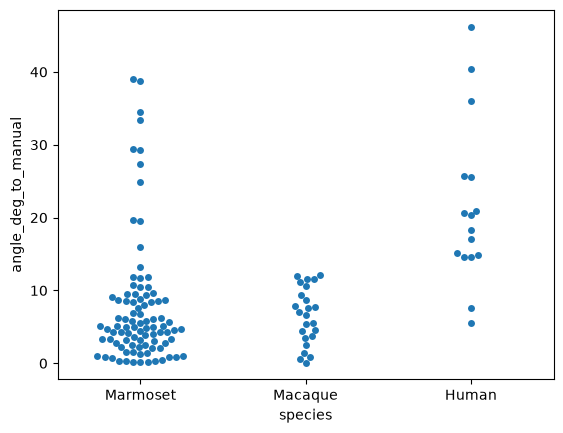

<Figure size 640x480 with 0 Axes>

In [16]:
gradient_results["angle_deg"] = (180./(np.pi))*gradient_results.angle
gradient_results["theta"] = gradient_results.angle.values

gradient_results["angle_deg_to_manual"] = (180./(np.pi))*gradient_results.angle_to_manual
gradient_results["theta_to_manual"] = gradient_results.angle_to_manual.values
gradient_results["angle_deg_of_manual"] = (180./(np.pi))*gradient_results.angle_of_manual

plt.figure()
sns.swarmplot(gradient_results, x ="species", y = "angle_deg")
for ii in range(3):
    plt.plot([ii-0.2,ii+0.2],np.ones([2,1])* gradient_results.loc[gradient_results.species==LIST_TO_RUN[ii]["species"],:].angle_deg_of_manual.values[0],'r-')
plt.ylim([0,180])

plt.savefig("/scratch/figure_4_panels/SUPP_angle_distribution.svg")
plt.figure()
plt.plot(gradient_results.loc[gradient_results.species=="Marmoset",:].z, gradient_results.loc[gradient_results.species=="Marmoset",:].angle_deg,'.')

plt.figure()
sns.swarmplot(gradient_results, x ="species", y = "angle_deg_to_manual")

plt.savefig("/scratch/figure_4_panels/SUPP_angle_distribution_to_manual.svg")
plt.figure()



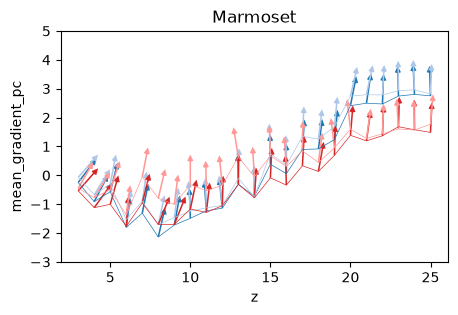

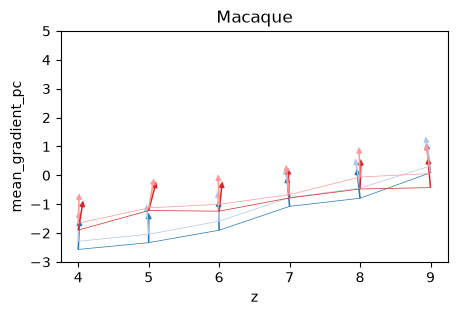

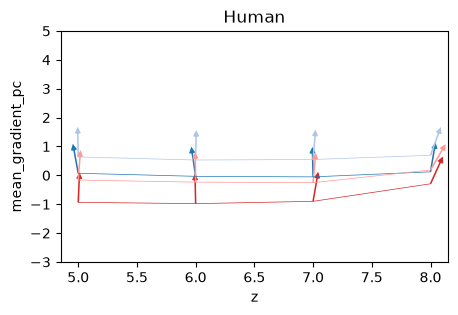

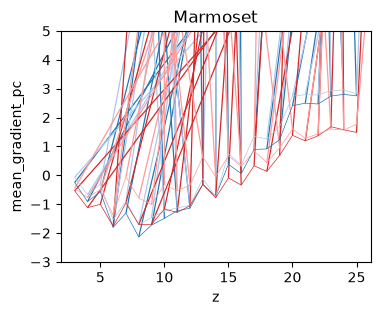

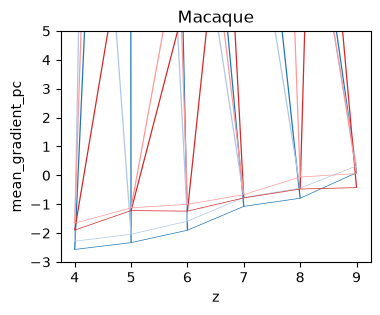

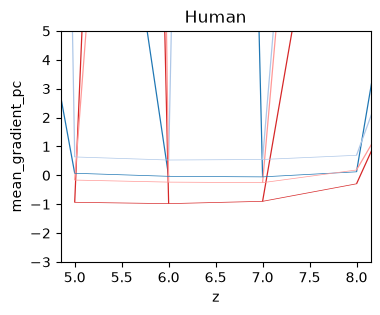

In [17]:

def _to_float_scalar(v):
    """Return a Python float from scalars or 1-element numpy/pandas containers."""
    arr = np.asarray(v)
    if arr.ndim == 0:
        return float(arr)
    if arr.size == 1:
        return float(arr.reshape(-1)[0])
    raise ValueError(f"Expected scalar-like value, got shape {arr.shape}")


def plot_arrows(
    df: pd.DataFrame, x_col="z", y_col="mean_gradient_pc", angle_col_radians=None,
    arrow_length: float = 30.0,
    color: str = "steelblue",
    ax: plt.Axes = None, label="None",
    title: str = "Arrow Field", angle_offset=0, xlim=None, ylim=None
) -> plt.Axes:
    """
    Plot fixed-length arrows at (x, y) positions with angles given by theta.

    Parameters
    ----------
    df : pd.DataFrame
        Must contain columns x_col, y_col, and angle_col_radians (angle in radians).
    arrow_length : float
        The display length of every arrow in screen pixels. Default 30.
    color : str
        Arrow color. Default 'steelblue'.
    ax : matplotlib.axes.Axes, optional
        Axes to draw on. Creates a new figure if None.
    title : str
        Plot title.

    Returns
    -------
    ax : matplotlib.axes.Axes
    """
    if angle_col_radians is None:
        raise ValueError("angle_col_radians must be provided")

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))

    # Force 1D float arrays so matplotlib doesn't receive object/array scalars.
    x = np.asarray(df[x_col], dtype=float).reshape(-1)
    y = np.asarray(df[y_col], dtype=float).reshape(-1)
    theta = np.asarray(df[angle_col_radians], dtype=float).reshape(-1)

    dx = np.cos(theta + float(angle_offset))
    dy = np.sin(theta + float(angle_offset))

    ax.plot(x, y, color=color, linewidth=0.5, label=label)
    ax.quiver(
        x,
        y,
        dx,
        dy,
        angles="uv",        # dx/dy are direction components, not data-space vectors
        scale_units="dots", # scale in screen pixels so length is axis-independent
        scale=1 / float(arrow_length),
        color=color,
        width=0.004,         # shaft width as fraction of axes width
        headwidth=4,
        headlength=4,
    )

    ax.set_title(title)
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)

    if xlim is not None and len(xlim) == 2:
        ax.set_xlim(_to_float_scalar(xlim[0]), _to_float_scalar(xlim[1]))
    if ylim is not None and len(ylim) == 2:
        ax.set_ylim(_to_float_scalar(ylim[0]), _to_float_scalar(ylim[1]))

    return ax


global_mean_angle = gradient_results.theta.mean()

for s in gradient_results.species.unique():
    fig, ax = plt.subplots(figsize=[5, 3])

    # Keep explicit float scalars for matplotlib compatibility across versions.
    ylim = [-3.0, 5.0]



    for g in gradient_results.Group.unique():
        plot_arrows(
            gradient_results.loc[(gradient_results.Group == g) & (gradient_results.species == s), :],
            angle_col_radians="theta", arrow_length=30, title=s, ax=ax,
            color=CURRENT_COLOR_DICT_OF_DICTS["Group"][g], angle_offset=global_mean_angle,
            ylim=ylim,
        )

    plt.savefig("/scratch/figure_4_panels/FIGURE_4_"+LAYER_TO_USE+"_"+s+"_gradient_direction.png",dpi=900)
    plt.savefig("/scratch/figure_4_panels/FIGURE_4_"+LAYER_TO_USE+"_"+s+"_gradient_direction.svg",dpi=900)

for s in gradient_results.species.unique():
    fig, ax = plt.subplots(figsize=[4, 3])

    # Keep explicit float scalars for matplotlib compatibility across versions.
    ylim = [-3.0, 5.0]

    for g in gradient_results.Group.unique():
        plot_arrows(
            gradient_results.loc[(gradient_results.Group == g) & (gradient_results.species == s), :],
            angle_col_radians="theta", arrow_length=300, title=s, ax=ax,
            color=CURRENT_COLOR_DICT_OF_DICTS["Group"][g], angle_offset=global_mean_angle,
            ylim=ylim,
        )
    plt.savefig("/scratch/figure_4_panels/FIGURE_4_"+LAYER_TO_USE+"_"+s+"_gradient_direction.png",dpi=900)
    plt.savefig("/scratch/figure_4_panels/FIGURE_4_"+LAYER_TO_USE+"_"+s+"_gradient_direction.svg",dpi=900)


In [18]:
genes = ['CNR1', 'GDA', 'ST6GALNAC5', 'TESPA1', "PROX1"]
possible_genes = ["CNR1", 'GDA', "ARHGAP6", "CRYM","COL25A1", "TESPA1"]
more_genes = ["CNR1","SPOCK1","CRYM",  'GDA', 'PROX1', 'CCDC85A', 'TESPA1', 'RGS6',"ARHGAP6","GDA", "COL25A1"]


species_gene_lists = []
for res in zip([dorsal_spn_results],["dorsal SPNs"]): 

    
    for species in ["Marmoset","Macaque","Human"]:

        subset = res[0]["species_slice_ads"][species]

        even_more = [dr["top_genes_pc_best"].tolist() for dr in res[0]["gene_sets"] if dr["species"]==species][0]

        genes_we_have = list(set([g for g in genes+possible_genes+more_genes+even_more if g in subset.var_names]))
        species_gene_lists.append(genes_we_have)


['CRYM', 'LMO1', 'PLCXD3', 'L3MBTL4', 'MPPED1', 'LOC100385731', 'CCDC85A', 'GULP1', 'SCN4B', 'ABLIM1', 'JCAD', 'GPRIN3', 'TESPA1', 'GDA', 'SPOCK1', 'LHFPL6', 'SPON1', 'CSGALNACT1', 'CNR1', 'PPP1R1B', 'GLRA3', 'ST6GALNAC5', 'SYT10', 'FAM135B', 'PROX1']
<class 'str'>
(18, 20)
(20,)
(20,)
<class 'pandas.core.frame.DataFrame'>
after subsetting
(18, 17)


/code/bg_spatial_plots/gradient_utils.py:535: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_cell_counts = heatmap_data.groupby('distance_bin').count().values[:,0]
/code/bg_spatial_plots/gradient_utils.py:536: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  heatmap_data_binned = heatmap_data.groupby('distance_bin').mean()


<class 'str'>
(18, 20)
(20,)
(20,)
<class 'pandas.core.frame.DataFrame'>
after subsetting
(18, 17)


/code/bg_spatial_plots/gradient_utils.py:535: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_cell_counts = heatmap_data.groupby('distance_bin').count().values[:,0]
/code/bg_spatial_plots/gradient_utils.py:536: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  heatmap_data_binned = heatmap_data.groupby('distance_bin').mean()


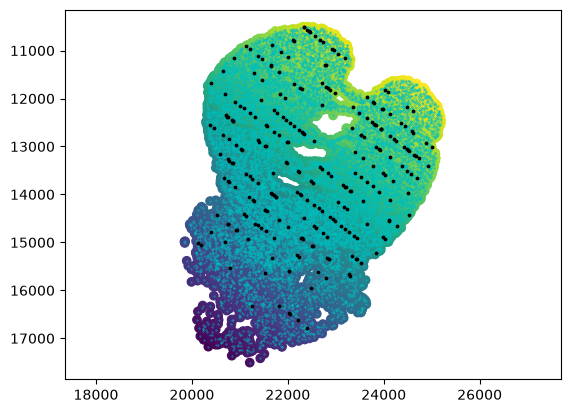

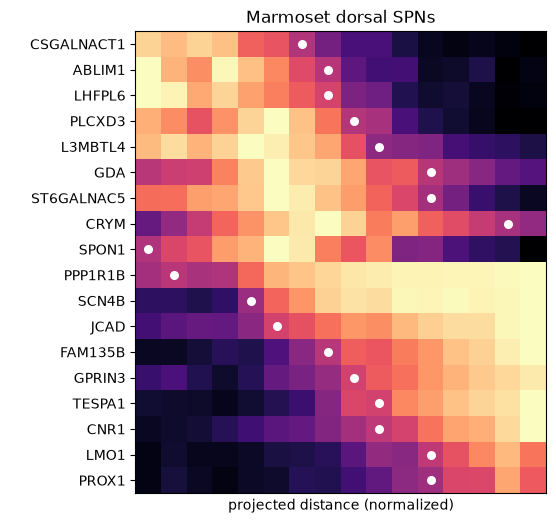

['SYT2', 'COL25A1', 'GULP1', 'SLC24A2', 'BRINP3', 'MOXD1', 'MME', 'HTR2C', 'CHRM3', 'NELL1', 'SEMA3E', 'TESPA1', 'GDA', 'HPCA', 'SNTG2', 'COL5A2', 'KCTD17', 'PRKG1', 'CSGALNACT1', 'CNR1', 'DPP10', 'ALCAM', 'PMFBP1', 'PPP1R1B', 'ST6GALNAC5', 'PROX1']
<class 'str'>
(18, 20)
(20,)
(20,)
<class 'pandas.core.frame.DataFrame'>
after subsetting
(18, 16)


/code/bg_spatial_plots/gradient_utils.py:535: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_cell_counts = heatmap_data.groupby('distance_bin').count().values[:,0]
/code/bg_spatial_plots/gradient_utils.py:536: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  heatmap_data_binned = heatmap_data.groupby('distance_bin').mean()


<class 'str'>
(18, 20)
(20,)
(20,)
<class 'pandas.core.frame.DataFrame'>
after subsetting
(18, 16)


/code/bg_spatial_plots/gradient_utils.py:535: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_cell_counts = heatmap_data.groupby('distance_bin').count().values[:,0]
/code/bg_spatial_plots/gradient_utils.py:536: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  heatmap_data_binned = heatmap_data.groupby('distance_bin').mean()


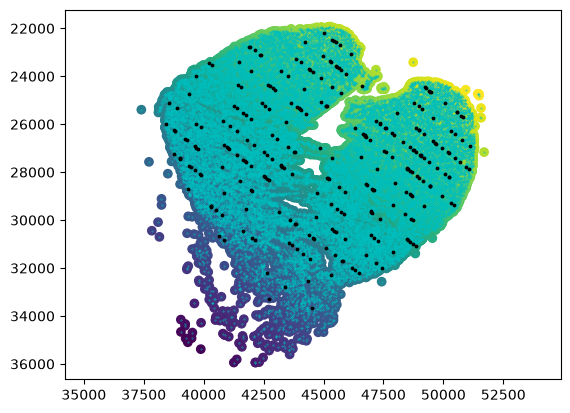

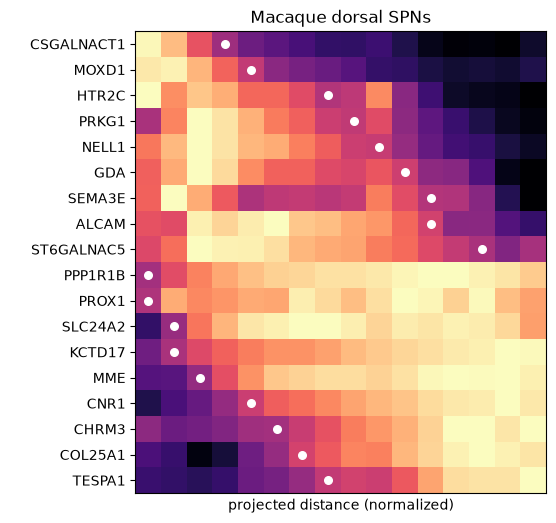

['COL5A3', 'ADORA2A', 'CCDC85A', 'GRIK3', 'PDE10A', 'CHRM3', 'MEIS3', 'LOXHD1', 'RGS4', 'HS3ST4', 'ARHGAP6', 'CA12', 'TESPA1', 'GDA', 'NEFM', 'SLC35F1', 'KCTD12', 'PDE1C', 'LINGO2', 'CNR1', 'TUNAR', 'KCNIP1', 'LPL', 'LYPD1', 'RGS6', 'PROX1']
<class 'str'>
(19, 20)
(20,)
(20,)
<class 'pandas.core.frame.DataFrame'>
after subsetting
(19, 20)


/code/bg_spatial_plots/gradient_utils.py:535: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_cell_counts = heatmap_data.groupby('distance_bin').count().values[:,0]
/code/bg_spatial_plots/gradient_utils.py:536: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  heatmap_data_binned = heatmap_data.groupby('distance_bin').mean()


<class 'str'>
(19, 20)
(20,)
(20,)
<class 'pandas.core.frame.DataFrame'>
after subsetting
(19, 20)


/code/bg_spatial_plots/gradient_utils.py:535: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_cell_counts = heatmap_data.groupby('distance_bin').count().values[:,0]
/code/bg_spatial_plots/gradient_utils.py:536: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  heatmap_data_binned = heatmap_data.groupby('distance_bin').mean()


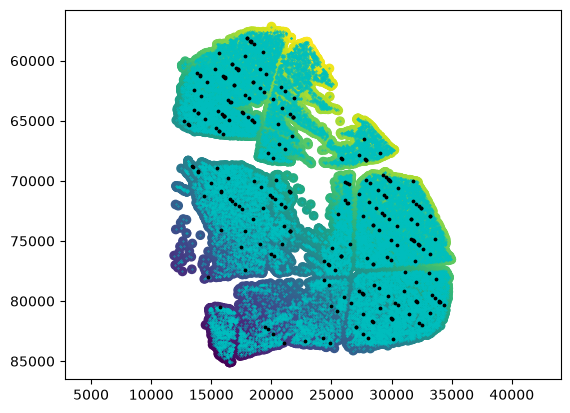

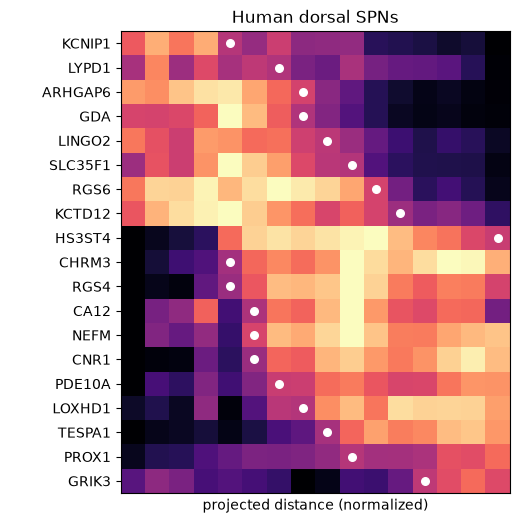

In [ ]:
# now the heatmap:
n_bins=20
min_cells=100
MAX_BINS_TO_KEEP=16

MIN_PROJ_PERCENTILE = 0


genes_to_drop =["MPPED1","CCDC85A","GLRA3","LOC100385731", "TUNAR","ADORA2A", "STNG2",
                "PMFBP1","COL5A3","BRINP3","PDE1C","LPL","SYT2","COL5A2","SNTG2","HPCA","DPP10", "MEIS3","SPOCK1","GULP1", "SYT10"]

#for res in zip([dorsal_spn_results, all_spn_results],["dorsal SPNs", "all SPNs"]):
for res in zip([dorsal_spn_results],["dorsal SPNs"]): 

    
    for species in ["Marmoset","Macaque","Human"]:

        even_more = [dr["top_genes_pc_best"].tolist() for dr in res[0]["gene_sets"] if dr["species"]==species][0]

        subset_0 = res[0]["species_slice_ads"][species].copy()

        genes_we_have = list(set([str(g) for g in genes+possible_genes+more_genes+even_more if g in subset_0.var_names]))


        # can be used to filter out one end of the depths 
        min_proj_length = np.percentile(subset_0.obs.proj_lengths,MIN_PROJ_PERCENTILE)
        subset= subset_0[subset_0.obs.proj_lengths>=min_proj_length,:]
        

        # run this to get bin_centers
        fig, ax = plt.subplots(figsize=(6,6))
        print(genes_we_have)
        genes_we_have = [g for g in genes_we_have if g not in genes_to_drop]
        ax, summary, bin_centers = plot_gene_depth_heatmap(subset, genes_we_have, n_bins=n_bins,min_cells=min_cells,
                                                         ordering_method='half-max', layer = LAYER_TO_USE,max_bins_to_keep=MAX_BINS_TO_KEEP,
                                                        show_summary_points='crossing', ax=ax)
        ax.tick_params(axis='x', bottom=False, labelbottom=False)
        plt.close()

        plt.figure()

        plt.scatter(subset_0.obs.x_slab_um, subset_0.obs.y_slab_um, c = subset_0.obs.proj_lengths)

   

        plt.scatter(subset.obs.x_slab_um, subset.obs.y_slab_um, s=.1,c = 'c')
        # add little strips of black cells to show bin edges
        for bin_ in bin_centers:
            bin_mask = np.abs(subset_0.obs.proj_lengths-bin_)<3.

            plt.scatter(subset_0.obs.x_slab_um[bin_mask], subset_0.obs.y_slab_um[bin_mask],s=3, c = 'k')
        plt.axis('equal')
        plt.gca().set_yinverted(True)

        plt.savefig("/root/capsule/scratch/figure_4_panels/SUPP_scatterplot_"+LAYER_TO_USE+"_"+res[1]+"_"+species+"_depth_heatmap.png", dpi=900,bbox_inches='tight')
        plt.savefig("/root/capsule/scratch/figure_4_panels/SUPP_scatterplot_"+LAYER_TO_USE+"_"+res[1]+"_"+species+"_depth_heatmap.svg",bbox_inches='tight')


        fig, ax = plt.subplots(figsize=(6,6))

        ax, summary, bin_centers = plot_gene_depth_heatmap(subset, genes_we_have, n_bins=n_bins,min_cells=min_cells,
                                                         ordering_method='half-max', layer = LAYER_TO_USE, max_bins_to_keep=MAX_BINS_TO_KEEP,
                                                        show_summary_points='crossing', ax=ax, pad_gene_names=15)
        ax.tick_params(axis='x', bottom=False, labelbottom=False)
        plt.title(species+" "+res[1])
        plt.savefig("/root/capsule/scratch/figure_4_panels/FIGURE_4_"+LAYER_TO_USE+"_"+res[1]+"_"+species+"_depth_heatmap.svg")
        plt.savefig("/root/capsule/scratch/figure_4_panels/FIGURE_4_"+LAYER_TO_USE+"_"+res[1]+"_"+species+"_depth_heatmap.png", dpi=900,bbox_inches='tight')

        plt.show()

